In [1]:
import json
import os
from pathlib import Path
from src.audio import load_audio, rms_db
import src.config as config
from src.dataset import get_embeddings, TestDataset, PrecomputedDataset, mashup_collate_fn, test_collate_fn
from src.models import EffNetB0
from src.utils import get_train_stats
from src.metrics import compute_fid
import librosa
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import random
from sklearn.manifold import TSNE

## Basic checks

First off, how many files are there in the datasets?

In [2]:
stems = [f for f in Path(config.STEMS_DIR).rglob("*.wav")]
genres = sorted([p for p in Path(config.STEMS_DIR).iterdir()])
noises = sorted([f for f in Path(config.NOISE_DIR).iterdir() if f.is_file()])
test_paths = sorted([f for f in Path(config.TEST_DIR).iterdir() if f.is_file()])

print(f"Stems: {len(stems)}")
print(f"Genres: {len(genres)} ({[p.name for p in genres]})")
print(f"Noises: {len(noises)}")
print(f"Test: {len(test_paths)}")

Stems: 4000
Genres: 10 (['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'])
Noises: 2000
Test: 3020


Taking a quick look at the audio files themselves:

In [3]:
print(f"Stem: SR={librosa.get_samplerate(stems[0])}, channels={librosa.load(stems[0], mono=False)[0].ndim}")
print(f"Noise: SR={librosa.get_samplerate(noises[0])}, channels={librosa.load(noises[0], mono=False)[0].ndim}")
print(f"Test: SR={librosa.get_samplerate(test_paths[0])}, channels={librosa.load(test_paths[0], mono=False)[0].ndim}")

Stem: SR=44100, channels=2
Noise: SR=44100, channels=1
Test: SR=22050, channels=1


- The GTZAN stems are sampled at 44.1 kHz in stereo.
- The noises are sampled at 44.1 kHz in mono.
- The test mashups are sampled at 22.05 kHz in mono.

So the stems need to be loaded as mono (by averaging across the channels), which `librosa` does by default when loading `.wav`s. Also, I'll resample *all* the audio files to 22050 Hz across the board, just to simplify things - the extra fidelity doesn't really matter for a task like this, and it'll save on disk space and training time.

Let's a) quickly verify that all the stem files are valid, and b) see the genre breakdown:

In [4]:
for g in genres:
    dirs = sorted([p for p in g.iterdir() if p.is_dir()])
    print(f"{g.name}: {len(dirs)} songs")
    for d in dirs:
        files = [f for f in d.iterdir() if f.is_file()]
        if len(files) != 4:
            print(f"WARNING: {d} doesn't contain all 4 stems.")
        for f in files:
            if os.stat(f).st_size < 4096: # Should be larger than 4 KB
                print(f"WARNING: {f} is likely corrupt.")
            if librosa.get_samplerate(f) != 44100:
                print(f"WARNING: {f} has a mismatched sample rate.")

blues: 100 songs
classical: 100 songs
country: 100 songs
disco: 100 songs
hiphop: 100 songs
jazz: 100 songs
metal: 100 songs
pop: 100 songs
reggae: 100 songs
rock: 100 songs


So the song stems are perfectly class-balanced, and there are no missing or invalid stems.

What about the noises? ESC-50 includes an `esc50.csv` that contains metadata about the whole dataset. Let's load that into a dataframe.

In [5]:
noise_df = pd.read_csv("data/messy_mashup/ESC-50-master/meta/esc50.csv")
noise_df["category"].value_counts().sort_index(), noise_df["category"].nunique()

(category
 airplane            40
 breathing           40
 brushing_teeth      40
 can_opening         40
 car_horn            40
 cat                 40
 chainsaw            40
 chirping_birds      40
 church_bells        40
 clapping            40
 clock_alarm         40
 clock_tick          40
 coughing            40
 cow                 40
 crackling_fire      40
 crickets            40
 crow                40
 crying_baby         40
 dog                 40
 door_wood_creaks    40
 door_wood_knock     40
 drinking_sipping    40
 engine              40
 fireworks           40
 footsteps           40
 frog                40
 glass_breaking      40
 hand_saw            40
 helicopter          40
 hen                 40
 insects             40
 keyboard_typing     40
 laughing            40
 mouse_click         40
 pig                 40
 pouring_water       40
 rain                40
 rooster             40
 sea_waves           40
 sheep               40
 siren               40
 sneez

So the noises are also class-balanced, with 40 samples each for 50 unique classes.

## Audio duration

In [6]:
test_ids = [f.name.split(".")[0] for f in test_paths]
df = pd.DataFrame(zip(test_ids, test_paths), columns=["id", "path"])
df["duration"] = df["path"].apply(lambda p: librosa.get_duration(path=p, sr=config.SR))
df[["duration"]].describe()

,duration
count,3020.000000
mean,28.653240
std,3.773619
min,6.060408
25%,29.628662
50%,29.953741
75%,30.013333
max,30.579229


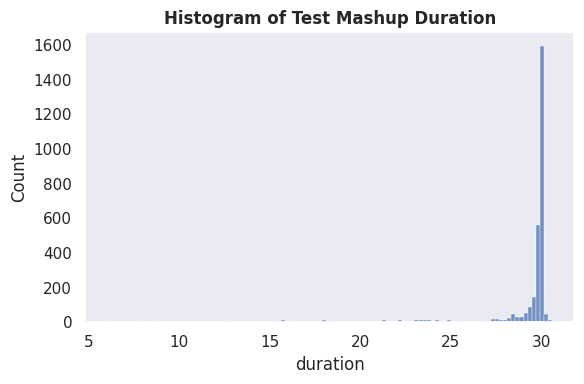

In [18]:
plt.figure(figsize=(6,4))
sns.histplot(data=df["duration"])
plt.title("Histogram of Test Mashup Duration", fontweight="bold")
plt.tight_layout()
plt.show()

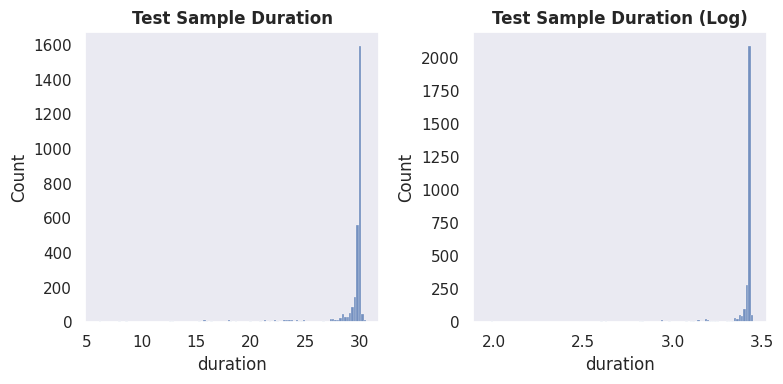

In [13]:
sns.set_theme()
sns.set_style("dark")
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
sns.histplot(data=df["duration"], ax=ax[0])
sns.histplot(data=np.log1p(df["duration"]), ax=ax[1])
ax[0].set_title("Test Sample Duration", fontweight="bold")
ax[1].set_title("Test Sample Duration (Log)", fontweight="bold")
plt.tight_layout()
plt.show()

So the test samples have varying durations, although the median duration is roughly 30s.

In [19]:
stem_durations = [librosa.get_duration(path=f, sr=config.SR) for f in stems]
pd.Series(stem_durations).describe()

count    4000.000000
mean       30.024047
std         0.080883
min        29.931973
25%        30.000181
50%        30.013333
75%        30.013333
max        30.648889
dtype: float64

The stems are all almost exactly 30s long.

In [20]:
noise_durations = [librosa.get_duration(path=f, sr=config.SR) for f in noises]
pd.Series(noise_durations).describe()

count    2000.0
mean        5.0
std         0.0
min         5.0
25%         5.0
50%         5.0
75%         5.0
max         5.0
dtype: float64

The noises are all exactly 5 seconds long.

Takeaway: I should use this information to decide what length of spectrograms I'll pass as input to my model(s), and whether or not I want to use sliding windows for training and inference.

## Audio loudness (RMS)

Another important aspect, especially when considering normalization/standardization.

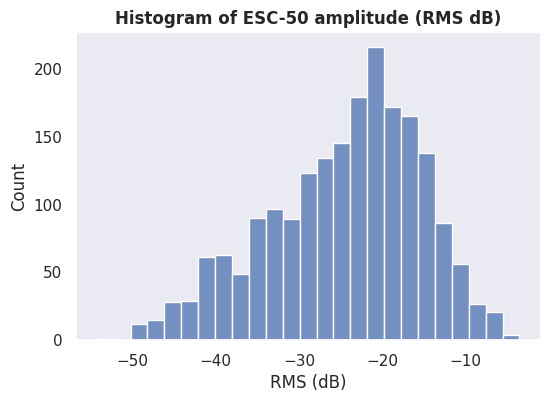

In [ ]:
noise_rmses = [rms_db(load_audio(path=f, sr=config.SR)) for f in noises]
plt.figure(figsize=(6,4))
sns.histplot(noise_rmses)
plt.title("Histogram of ESC-50 amplitude (RMS dB)", fontweight="bold")
plt.xlabel("RMS (dB)")
plt.show()

In [25]:
pd.Series(noise_rmses).describe()

count    2000.000000
mean      -24.604259
std         9.203545
min       -54.283260
25%       -30.632715
50%       -22.962727
75%       -17.806120
max        -3.546812
dtype: float64

So the noise files tend to be quite loud on the whole, with the median hovering at around -20 dB, but there's a lot of variability, as the standard deviation is ~9.2 dB.

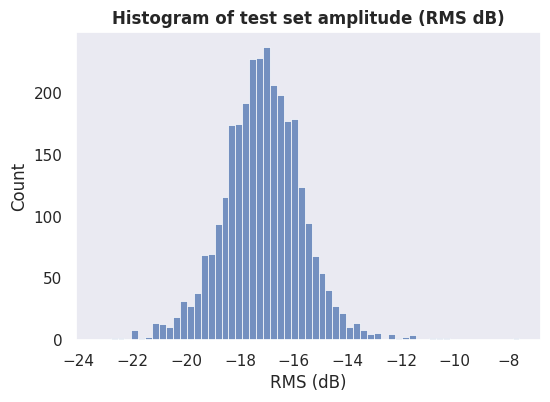

In [ ]:
test_rmses = [rms_db(load_audio(path=f, sr=config.SR)) for f in test_paths]
plt.figure(figsize=(6,4))
sns.histplot(test_rmses)
plt.title("Histogram of test set amplitude (RMS dB)", fontweight="bold")
plt.xlabel("RMS (dB)")
plt.show()

In [28]:
pd.Series(test_rmses).describe()

count    3020.000000
mean      -17.146095
std         1.555617
min       -23.330507
25%       -18.071653
50%       -17.152581
75%       -16.193314
max        -7.595422
dtype: float64

The test audio files are actually *really* loud - even louder than the noise files, on average - and the distribution is in quite a narrow range, with a standard deviation of ~1.6 dB. The median is around -17 dB, and even the quietest file is -23 dB. So that's good to know - the test mashups lean much louder than I would've expected, and I'll need to take that into account when generating the synthetic training data.

Next, loudness by genre and stem.

In [29]:
rows = []
for p in stems:
    s = str(p).split("/")
    genre = s[3]
    song = s[4]
    stem = s[5].split(".")[0]
    rms = rms_db(load_audio(path=p, sr=config.SR)[0])
    rows.append((genre, song, stem, rms))

df_stems = pd.DataFrame(rows, columns=["genre", "song", "stem", "rms_db"])
print(len(df_stems))
df_stems

4000


,genre,song,stem,rms_db
0,rock,rock.00085,bass,-80.000000
1,rock,rock.00085,drums,-80.000000
2,rock,rock.00085,other,-55.143341
3,rock,rock.00085,vocals,-38.598370
4,rock,rock.00041,bass,-71.197174
...,...,...,...,...
3995,reggae,reggae.00089,vocals,-60.672974
3996,reggae,reggae.00020,bass,-22.022886
3997,reggae,reggae.00020,drums,-43.575943
3998,reggae,reggae.00020,other,-52.035248


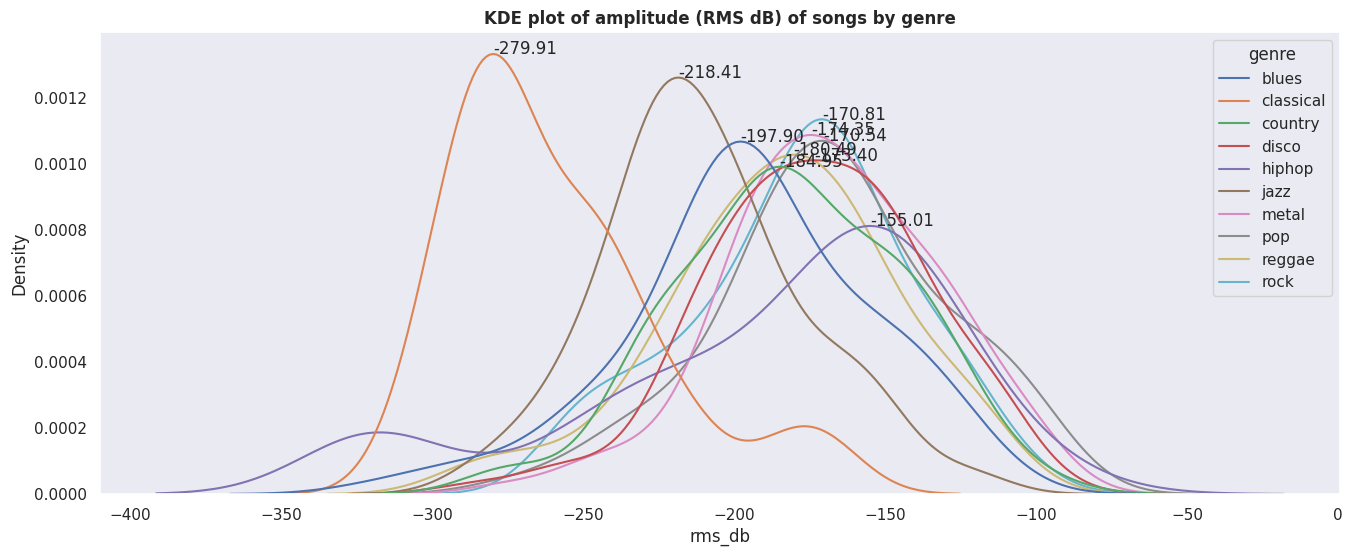

In [37]:
temp = df_stems.groupby(by=["genre", "song"], as_index=False)["rms_db"].agg(np.sum)
plt.figure(figsize=(16,6))
ax = sns.kdeplot(temp, x="rms_db", hue="genre")
for line in ax.lines:
    x_data, y_data = line.get_data()
    mode_x = x_data[np.argmax(y_data)]
    mode_y = y_data[np.argmax(y_data)]
    ax.annotate(f"{mode_x:.2f}", xy=(mode_x, mode_y))
plt.title("KDE plot of amplitude (RMS dB) of songs by genre", fontweight="bold")
plt.show()

I just summed the four stems that make up each song, then compared the RMS values of songs by genre. Some interesting observations:

- Classical (orange) is by far the quietest genre, with a mode RMS value of around -280 dB. This makes sense, given there's probably a lack of loud instruments or vocals dominating a song.
- Jazz (brown) is the secondest quietest, with a mode RMS value of around -218 dB.
- Hip-hop (purple) has a much wider RMS spread than the other genres, and a shorter peak, so the loudness fluctuates a lot from file to file.

The plots for the remaining genres overlap considerably, and there's not much to be gleaned from there.

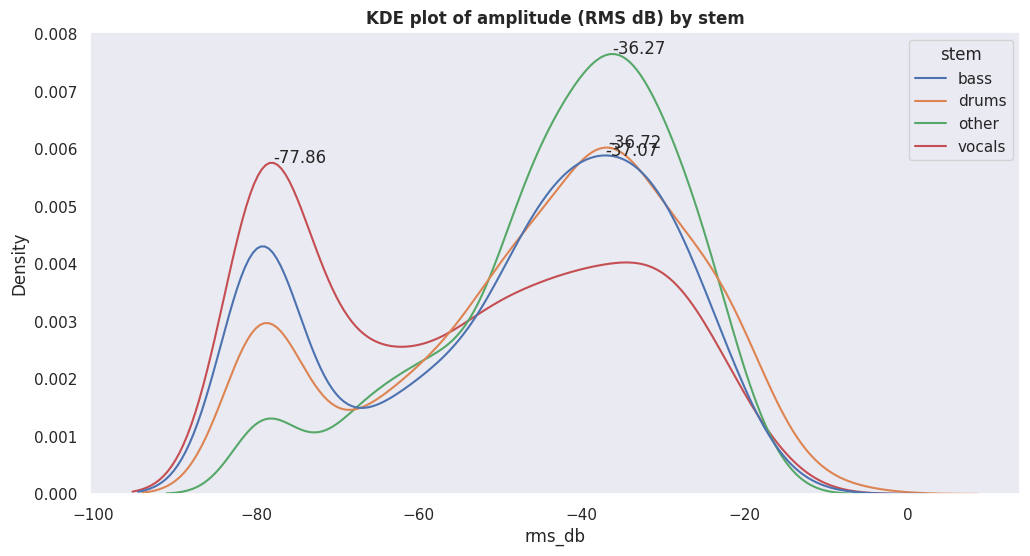

In [35]:
plt.figure(figsize=(12,6))
ax = sns.kdeplot(df_stems, x="rms_db", hue="stem")
for line in ax.lines:
    x_data, y_data = line.get_data()
    mode_x = x_data[np.argmax(y_data)]
    mode_y = y_data[np.argmax(y_data)]
    ax.annotate(f"{mode_x:.2f}", xy=(mode_x, mode_y))
plt.title("KDE plot of amplitude (RMS dB) by stem", fontweight="bold")
plt.show()

There are two clear modes for each type of stem. For the peak at around -78 dB, an RMS that low indicates those stem files are mostly silent for the 30 seconds, or just extremely quiet. That makes sense: some genres might not utilize certain stem types much. For example, I assume the classical music files are very likely to have no vocals or drums (or minimal).

As for the other peak at around -36 dB, all the stems seem to follow fairly similar patterns. Nothing too helpful there.

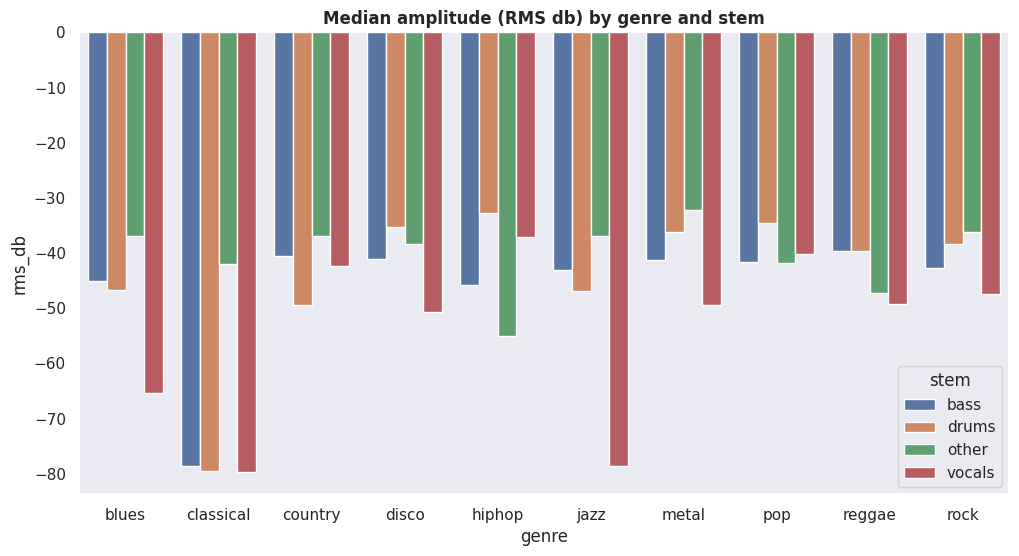

In [42]:
temp = df_stems.groupby(by=["genre", "stem"], as_index=False)["rms_db"].median()
plt.figure(figsize=(12,6))
sns.barplot(temp, y="rms_db", x="genre", hue="stem")
plt.title("Median amplitude (RMS db) by genre and stem", fontweight="bold")
plt.show()

This is useful information. Keeping in mind that lower dB values are quieter:

- Classical, jazz, and blues tracks don't utilize vocal tracks much, if at all. The median for classical and jazz are around 80 dB, or near silence. Makes sense - instruments like piano, violin, guitar, sax, etc. all fall under "other".
- Classical songs more or less only make use of the "other" tracks.
- Hip-hop has the heaviest vocal emphasis of all genres.
- Reggae and rock have quite similar instrument loudness distributions, so models might get struggle to discriminate between the two.

In [ ]:
def get_features(path, sr=config.SR, n_fft=config.N_FFT, hop_length=config.HOP_LENGTH):
    y = load_audio(path, sr=sr)
    duration = len(y)/sr
    rmsdb = rms_db(y)
    zcr = librosa.feature.zero_crossing_rate(y=y, hop_length=hop_length)[0].mean()
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length)[0].mean()
    flatness = librosa.feature.spectral_flatness(y=y, n_fft=n_fft, hop_length=hop_length)[0].mean()
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, roll_percent=0.85)[0].mean()
    return dict(duration=duration, rms_db=rmsdb, zcr=zcr, centroid=centroid, flatness=flatness, rolloff=rolloff)

In [221]:
features = [get_features(f) for f in test_paths]

In [224]:
ft_df = pd.DataFrame.from_dict(features)
ft_df.describe()

,duration,rms_db,zcr,centroid,flatness,rolloff
count,3020.000000,3020.000000,3020.000000,3020.000000,3020.000000,3020.000000
mean,28.653240,-17.146095,0.106069,2288.680010,0.022167,4757.699028
std,3.773619,1.555617,0.038342,586.605961,0.016364,1238.528472
min,6.060408,-23.330507,0.007506,433.976796,0.000150,712.460915
25%,29.628662,-18.071653,0.079992,1901.672551,0.010532,3934.649275
50%,29.953741,-17.152581,0.103493,2272.557383,0.018120,4776.839060
75%,30.013333,-16.193314,0.128773,2663.163209,0.029710,5574.531133
max,30.579229,-7.595422,0.304043,4472.006211,0.127426,8248.715628


## Analyzing my synthetic datasets

### Class balance
I want to verify that my (final) synthetic training and validation datasets are at least roughly class-balanced, since I picked a random genre for each generated sample and didn't enforce an exact split for each genre.

In [43]:
with open("precomputed/train_v4_list.txt", "r") as f:
    train_paths = [l.strip() for l in f if l.strip()]

train_genres = []
train_songs = []
for p in train_paths:
    npz = np.load(p, mmap_mode="r")
    meta = json.loads(str(npz["meta"]))
    train_genres.append(meta["genre"])
    train_songs.append(meta["songs"])

df_train = pd.DataFrame([train_paths, train_genres, train_songs]).T
df_train.columns = ["path", "genre", "songs"]
print(df_train.shape)
print(df_train["genre"].value_counts())

(10000, 3)
genre
blues        1060
rock         1022
disco        1013
reggae       1007
pop          1005
classical    1002
metal        1002
country       998
jazz          963
hiphop        928
Name: count, dtype: int64


In [45]:
with open("precomputed/val_v4_list.txt", "r") as f:
    val_paths = [l.strip() for l in f if l.strip()]

val_genres = []
val_songs = []
for p in val_paths:
    npz = np.load(p, mmap_mode="r")
    meta = json.loads(str(npz["meta"]))
    val_genres.append(meta["genre"])
    val_songs.append(meta["songs"])

df_val = pd.DataFrame([val_paths, val_genres, val_songs]).T
df_val.columns = ["path", "genre", "songs"]
print(df_val.shape)
print(df_val["genre"].value_counts())

(2000, 3)
genre
pop          217
blues        216
classical    209
reggae       206
disco        197
jazz         194
rock         194
hiphop       190
metal        189
country      188
Name: count, dtype: int64


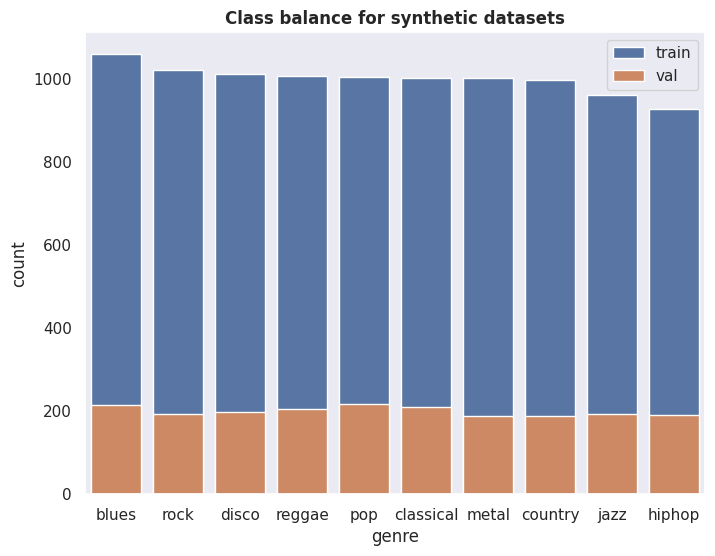

In [50]:
plt.figure(figsize=(8,6))
sns.barplot(df_train["genre"].value_counts(), label="train")
sns.barplot(df_val["genre"].value_counts(), label="val")
plt.legend()
plt.title("Class balance for synthetic datasets", fontweight="bold")
plt.show()

That's close enough for my liking. No need to enforce exact genre counts or re-synthesize the datasets. If a model struggles to distinguish certain genres later, I can always either oversample from the data or tweak the cross-entropy loss function's class weights.

### Comparing synth and test distributions

Now for the important part. First, I'm going to load my final (modified) EfficientNet_B0 model weights, then pass my synthetic training data and the test data and extract the model embeddings (just before the classifier head) for both.

In [ ]:
mean, std = get_train_stats(config.TRAIN_STATS_PATH)
test_files = sorted([f for f in Path(config.TEST_DIR).iterdir() if f.is_file()])

test_set = TestDataset(test_files, mean=mean, std=std)
train_set = PrecomputedDataset("precomputed/train_v4_list.txt", mean=mean, std=std)

effnet_finetuned = EffNetB0(num_classes=10, pretrained=False, freeze_backbone=True)
ckpt = torch.load(Path(config.CHECKPOINTS_DIR) / "effnetb0.ckpt", map_location="cpu", weights_only=False)
effnet_finetuned.load_state_dict(ckpt["model_state"])

test_loader = DataLoader(
    dataset=test_set,
    batch_size=16,
    shuffle=False,
    num_workers=8,
    pin_memory=False,
    collate_fn=test_collate_fn
)

train_loader = DataLoader(
    dataset=train_set,
    batch_size=16,
    shuffle=False,
    num_workers=8,
    pin_memory=False,
    collate_fn=mashup_collate_fn,
)

test_embeddings = get_embeddings(model=effnet_finetuned, loader=test_loader)
train_embeddings = get_embeddings(model=effnet_finetuned, loader=train_loader)

np.savez("precomputed/embeddings.npz", test=test_embeddings, train=train_embeddings)

print(test_embeddings.shape, train_embeddings.shape)

(3020, 1280) (10000, 1280)
12.820257711172015


In [51]:
embeddings_npz = np.load("precomputed/embeddings.npz", mmap_mode="r")
train_embeddings, test_embeddings = embeddings_npz["train"], embeddings_npz["test"]

One of the metrics I used when ensuring the synthetic data process was correct.

In [52]:
print(compute_fid(train_embeddings, test_embeddings))

12.820257711172015


In [53]:
matplotlib.rcParams['axes.prop_cycle'] = matplotlib.cycler(color=["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "teal", "tab:olive", "tab:cyan"]) 

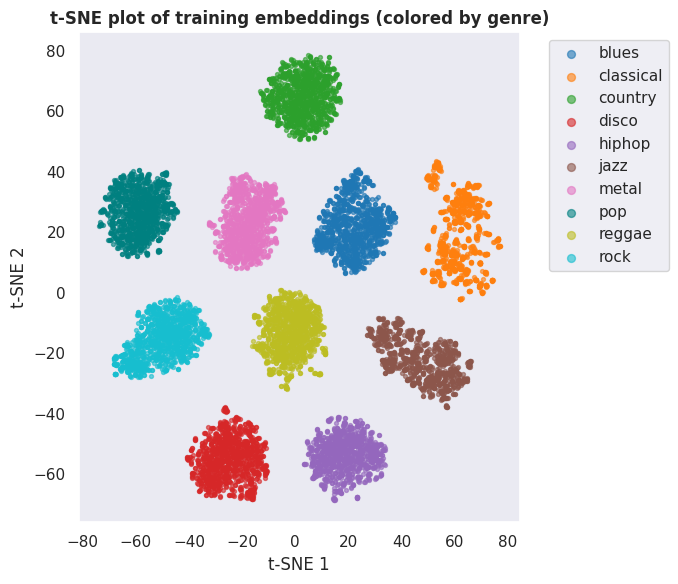

In [55]:
rng = random.Random()
tsne = TSNE(n_components=2, perplexity=30, random_state=0)
z2 = tsne.fit_transform(train_embeddings)
plt.figure(figsize=(7,6))

label = df_train["genre"].to_numpy()
for g in config.GENRES:
    idx = label == g
    plt.scatter(z2[idx, 0], z2[idx, 1], s=8, alpha=0.6, label=g)

plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("t-SNE plot of training embeddings (colored by genre)", fontweight="bold")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

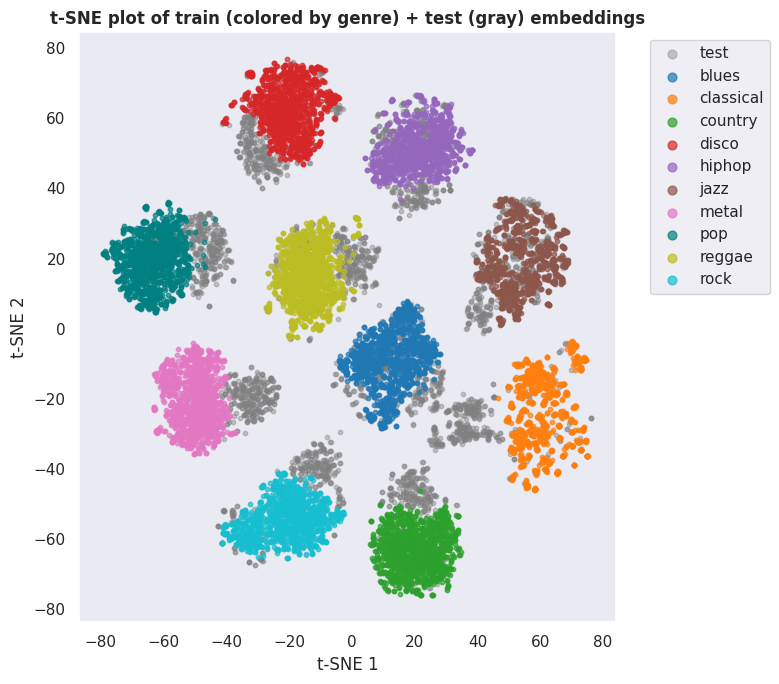

In [56]:
train_subset = rng.choices(train_embeddings, k=3020)
labels = np.array(["synth"]*len(train_subset) + ["test"]*len(test_embeddings))
Z_all = np.vstack([train_embeddings, test_embeddings])
Z_2d = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(Z_all)

# Split back
Z_train_2d = Z_2d[:len(train_embeddings)]
Z_test_2d  = Z_2d[len(train_embeddings):]

plt.figure(figsize=(8,7))

# Plot test first (background)
plt.scatter(Z_test_2d[:, 0], Z_test_2d[:, 1], s=10,  alpha=0.4, color="gray", label="test")

# Plot train per genre
lbl = df_train["genre"].to_numpy()
for g in config.GENRES:
    idx = lbl == g
    plt.scatter(Z_train_2d[idx, 0], Z_train_2d[idx, 1], s=10, alpha=0.7, label=g)

plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("t-SNE plot of train (colored by genre) + test (gray) embeddings", fontweight="bold")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

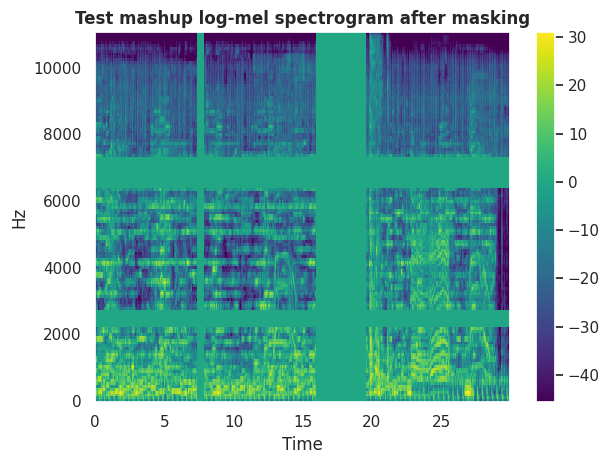

In [78]:
from src.train import spec_augment

_t = torch.from_numpy(np.load("precomputed/train_v4/00001.npz", mmap_mode="r")["mel"]).unsqueeze(0).unsqueeze(0)
librosa.display.specshow(data=spec_augment(_t).squeeze(0).squeeze(0).cpu().numpy(), x_axis="time", y_axis="hz", sr=config.SR, hop_length=config.HOP_LENGTH, cmap="viridis")
plt.title("Test mashup log-mel spectrogram after masking", fontweight="bold")
plt.tight_layout()
plt.colorbar()